# Multiple Linear Regression: When It Fits and When It Does Not

## 1. Introduction

This notebook studies multiple linear regression in two ways:

1. **Part A — linear probability model:** ordinary least squares (OLS) predicts the 0/1 diabetes label. This makes a direct comparison with the saved 70k logistic model, while showing why linear regression is not ideal for classification.
2. **Part B — BMI regression:** BMI is a continuous outcome, so multiple linear regression is a more suitable descriptive tool. We examine associations, not causes.

**Data sources:** MariaDB tables `diabetes_model_train` and `diabetes_model_test`; saved model `application/models/logreg_70k.joblib`.

**Leakage safeguards:** all scalers and fitted models learn from training rows only. The threshold is chosen from five-fold out-of-fold (OOF) training predictions. The held-out test table is opened only after model fitting and threshold selection, for final scoring.

**Outputs:** model comparison tables, diagnostic charts, `diabetes_eval_linprob_70k.csv`, a database table with the same results, and `linprob_70k.joblib` saved beside this notebook (never in `application/models`).

## 2. Import Libraries and Set Up the Database

We import the libraries for regression, diagnostics, plots and database access. A pipeline will fit feature scaling on training data only.

In [1]:
# Tables and model files are located relative to this notebook's folder.
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sqlalchemy import create_engine, text
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path("../..").resolve()
TARGET = "Diabetes_binary"
RANDOM_STATE = 42
TARGET_RECALL = 0.85          # working assumption, not a final group decision
REAL_PREVALENCE = 0.14        # approximate prevalence used for a separate illustration
NON_BINARY = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]
engine = create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")

# Keep plot styling consistent with the rest of the project.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print("Libraries and MariaDB connection configured.")

Libraries and MariaDB connection configured.


**Interpretation:** The saved model and MariaDB connection loaded successfully.

## 3. Prepare Part A: Load the 70k Model and Training Rows

We use the saved 70k model's feature list so the comparison changes only the modeling method. First we load training data and verify its dimensions and target balance. We deliberately do not read the test table yet.

In [2]:
# Load only the training table before fitting or choosing a threshold.
train_df = pd.read_sql("SELECT * FROM diabetes_model_train", con=engine)
logit_bundle = joblib.load(ROOT / "application/models/logreg_70k.joblib")
A_FEATURES = list(logit_bundle["features"])

# Verify that the table has the columns and class counts expected by this project's saved split.
missing = [name for name in [TARGET, *A_FEATURES] if name not in train_df.columns]
if missing:
    raise ValueError(f"Training table is missing required columns: {missing}")
if len(train_df) != 56_155:
    raise ValueError(f"Expected 56,155 training rows, found {len(train_df):,}.")

X_train = train_df[A_FEATURES].astype(float)
y_train = train_df[TARGET].astype(int)
prep_a = ColumnTransformer(
    [("scale", StandardScaler(), [c for c in A_FEATURES if c in NON_BINARY])],
    remainder="passthrough", verbose_feature_names_out=False
)
Z_train = prep_a.fit_transform(X_train)  # fitted on training rows only
A_NAMES = list(prep_a.get_feature_names_out())
Z_train_df = pd.DataFrame(Z_train, columns=A_NAMES, index=train_df.index)

summary = pd.DataFrame({
    "Item": ["Training rows", "Features from saved 70k bundle", "No diabetes", "Diabetes", "Saved logistic threshold"],
    "Value": [len(train_df), len(A_FEATURES), int((y_train == 0).sum()), int((y_train == 1).sum()),
              f"{logit_bundle['threshold']:.4f}"],
})
display(summary.style.hide(axis="index"))
print("Part A training data is ready; the test table remains unopened.")

Item,Value
Training rows,56155
Features from saved 70k bundle,14
No diabetes,28077
Diabetes,28078
Saved logistic threshold,0.3963


Part A training data is ready; the test table remains unopened.


**Interpretation:** The train split has 56,155 rows, balanced at 28,077 no-diabetes and 28,078 diabetes respondents. The current saved 70k bundle uses 14 features and a 0.3963 threshold.

## 4. Fit the Linear Probability Model with OLS

A **linear probability model** is OLS fitted to a binary 0/1 outcome. We fit it on standardized training predictors only. HC3 robust standard errors adjust uncertainty estimates when residual variance is not constant. We compare each linear coefficient's sign and rank with the saved logistic model's coefficient and odds ratio.

In [3]:
# Fit OLS to the standardized training predictors and attach HC3 robust standard errors.
Z_train_const = sm.add_constant(Z_train_df, has_constant="add")
ols_a = sm.OLS(y_train, Z_train_const).fit(cov_type="HC3")

# Read logistic coefficients from the saved pipeline in the same transformed column order.
logit_estimator = logit_bundle["model"].named_steps["model"]
logit_coef = pd.Series(logit_estimator.coef_[0], index=A_NAMES)
ols_ci = ols_a.conf_int()
coef_a = pd.DataFrame({
    "Feature": A_NAMES,
    "OLS coefficient (change in probability)": ols_a.params[A_NAMES].to_numpy(),
    "OLS 95% CI lower": ols_ci.loc[A_NAMES, 0].to_numpy(),
    "OLS 95% CI upper": ols_ci.loc[A_NAMES, 1].to_numpy(),
    "OLS p-value": ols_a.pvalues[A_NAMES].to_numpy(),
    "Logistic coefficient": logit_coef[A_NAMES].to_numpy(),
    "Logistic odds ratio": np.exp(logit_coef[A_NAMES].to_numpy()),
})
coef_a["OLS absolute-effect rank"] = coef_a["OLS coefficient (change in probability)"].abs().rank(ascending=False, method="min").astype(int)
coef_a["Logistic absolute-effect rank"] = coef_a["Logistic coefficient"].abs().rank(ascending=False, method="min").astype(int)
coef_a = coef_a.sort_values("OLS absolute-effect rank")
display(coef_a.round(4).style.hide(axis="index"))
print(f"OLS fitted on {len(y_train):,} training rows with {len(A_FEATURES)} predictors.")

Feature,OLS coefficient (change in probability),OLS 95% CI lower,OLS 95% CI upper,OLS p-value,Logistic coefficient,Logistic odds ratio,OLS absolute-effect rank,Logistic absolute-effect rank
HighBP,0.159400,0.150600,0.168300,0.000000,0.746700,2.110000,1,2
HvyAlcoholConsump,-0.130300,-0.146200,-0.114500,0.000000,-0.787400,0.455000,2,1
HighChol,0.114600,0.106700,0.122600,0.000000,0.600800,1.823500,3,4
GenHlth,0.112600,0.108000,0.117300,0.000000,0.608400,1.837400,4,3
BMI,0.082800,0.078500,0.087100,0.000000,0.502000,1.652100,5,5
Age,0.072000,0.068100,0.075800,0.000000,0.426100,1.531300,6,6
Sex,0.049400,0.042100,0.056700,0.000000,0.279100,1.322000,7,7
HeartDiseaseorAttack,0.046800,0.035900,0.057700,0.000000,0.226900,1.254700,8,8
DiffWalk,0.029800,0.019500,0.040100,0.000000,0.122900,1.130800,9,10
Stroke,0.020900,0.005800,0.036000,0.006600,0.126000,1.134300,10,9


OLS fitted on 56,155 training rows with 14 predictors.


**Interpretation:** HighBP has the largest positive OLS coefficient (+0.159 probability units per binary step), while HvyAlcoholConsump has the largest negative coefficient (−0.130). The logistic model ranks BMI, HighBP, health rating and age among its strongest positive associations. The negative alcohol coefficient is a survey association, not evidence that alcohol protects against diabetes.

## 5. Diagnose the Linear Probability Model

We check whether the fitted values stay in the valid probability range and whether residual variance is constant. The residual plot uses different colors for the two actual classes; the two horizontal bands are expected because the outcome is 0 or 1. VIF (variance inflation factor) checks whether predictors are redundant with each other.

Check,Result
Training predictions below 0,3.21%
Training predictions above 1,1.57%
Breusch-Pagan LM statistic,1837.577
Breusch-Pagan p-value,0
Highest VIF,GenHlth: 1.756


Feature,VIF
GenHlth,1.756000
PhysHlth,1.642000
DiffWalk,1.538000
HighBP,1.317000
Age,1.273000
Income,1.240000
MentHlth,1.237000
HeartDiseaseorAttack,1.186000
HighChol,1.158000
BMI,1.145000


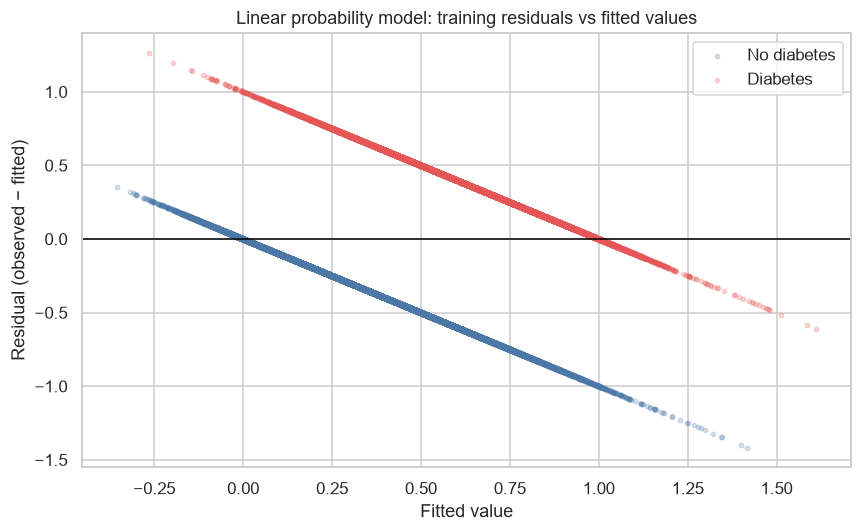

Training-only diagnostics complete.


In [4]:
# Training fitted values and residuals come only from the training fit.
train_fit_a = np.asarray(ols_a.fittedvalues)
train_resid_a = np.asarray(y_train) - train_fit_a
bp_a = het_breuschpagan(train_resid_a, Z_train_const)

# VIF is calculated from standardized training predictors (without the intercept).
vif_a = pd.DataFrame({
    "Feature": A_NAMES,
    "VIF": [variance_inflation_factor(Z_train_df.to_numpy(), i) for i in range(len(A_NAMES))],
}).sort_values("VIF", ascending=False)

diagnostic_a = pd.DataFrame({
    "Check": ["Training predictions below 0", "Training predictions above 1", "Breusch-Pagan LM statistic",
              "Breusch-Pagan p-value", "Highest VIF"],
    "Result": [f"{(train_fit_a < 0).mean():.2%}", f"{(train_fit_a > 1).mean():.2%}",
               f"{bp_a[0]:.3f}", f"{bp_a[1]:.3g}", f"{vif_a.iloc[0]['Feature']}: {vif_a.iloc[0]['VIF']:.3f}"],
})
display(diagnostic_a.style.hide(axis="index"))
display(vif_a.round(3).style.hide(axis="index"))

# Plot fitted value against residual; the class colors make the two bands visible.
fig, ax = plt.subplots(figsize=(8, 5))
for klass, color, label in [(0, "#4C78A8", "No diabetes"), (1, "#E45756", "Diabetes")]:
    mask = y_train.to_numpy() == klass
    ax.scatter(train_fit_a[mask], train_resid_a[mask], s=8, alpha=0.22, color=color, label=label)
ax.axhline(0, color="black", lw=1)
ax.set(title="Linear probability model: training residuals vs fitted values",
       xlabel="Fitted value", ylabel="Residual (observed − fitted)")
ax.legend()
plt.tight_layout()
plt.show()
print("Training-only diagnostics complete.")

**Interpretation:** The OLS model produces some invalid probabilities: 3.21% of training scores are below 0 and 1.57% above 1. The Breusch–Pagan test strongly rejects constant residual variance (p < 0.001). The highest VIF is 1.756, so severe predictor collinearity is not evident.

## 6. Fit the scikit-learn Pipeline and Check Training Scores

The pipeline repeats training-only scaling and fits `LinearRegression`. We compare it with the statsmodels fit and a mean-only dummy baseline on the training data. The held-out test table is not opened until the 85% recall threshold has been selected from out-of-fold training predictions in section 7.

In [5]:
# Define a pipeline so scaling is fitted inside every training fit.
def make_linear_regression(cols):
    scale_cols = [c for c in cols if c in NON_BINARY]
    preprocessor = ColumnTransformer(
        [("scale", StandardScaler(), scale_cols)], remainder="passthrough",
        verbose_feature_names_out=False
    )
    return Pipeline([("prep", preprocessor), ("model", LinearRegression())])

lpm_a = make_linear_regression(A_FEATURES).fit(train_df[A_FEATURES], y_train)
train_pred_a = lpm_a.predict(train_df[A_FEATURES])
max_difference = float(np.max(np.abs(train_pred_a - train_fit_a)))

# Fit the mean-only baseline using training data; report training metrics only at this stage.
dummy_a = DummyRegressor(strategy="mean").fit(train_df[A_FEATURES], y_train)
def regression_scores(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R-squared": r2_score(y, pred)}

training_rows=[]
for name, estimator in [("Mean baseline", dummy_a), ("Linear probability model", lpm_a)]:
    training_rows.append({"Model":name,"Split":"Training only",**regression_scores(y_train,estimator.predict(train_df[A_FEATURES]))})
regression_a_train_scores=pd.DataFrame(training_rows)
display(regression_a_train_scores.round(4).style.hide(axis="index"))
print(f"Maximum difference between statsmodels and scikit-learn training predictions: {max_difference:.3g}")
print(f"Training raw predictions below 0: {(train_pred_a < 0).mean():.2%}; above 1: {(train_pred_a > 1).mean():.2%}.")

Model,Split,MAE,RMSE,R-squared
Mean baseline,Training only,0.500000,0.500000,0.000000
Linear probability model,Training only,0.367600,0.424900,0.277700


Maximum difference between statsmodels and scikit-learn training predictions: 1.9e-14
Training raw predictions below 0: 3.21%; above 1: 1.57%.


**Interpretation:** Statsmodels and scikit-learn training predictions agree to 1.9e−14. On training data the linear model has MAE 0.3676, RMSE 0.4249 and R² 0.2777, compared with the mean baseline MAE 0.5000 and R² 0.

## 7. Use the Linear Probability Model as a Classifier

Although its raw outputs can fall outside 0–1, a threshold can turn them into class labels. We choose the 85% recall threshold from OOF training predictions only. The test table is used here only for final scoring. Clipped predictions are used for the Brier score, which requires probabilities between 0 and 1; ROC AUC uses the raw scores.

In [6]:
# Generate OOF predictions: each training row is scored by a model that did not fit that row.
cv_a = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_lpm_a = cross_val_predict(make_linear_regression(A_FEATURES), train_df[A_FEATURES], y_train,
                              cv=cv_a, method="predict")
precision_oof, recall_oof, thresholds_oof = precision_recall_curve(y_train, oof_lpm_a)
valid_thresholds = thresholds_oof[recall_oof[:-1] >= TARGET_RECALL]
threshold_lpm_a = float(valid_thresholds.max())

# The training-only threshold is now fixed, so we may open the held-out test table for final scoring.
test_df = pd.read_sql("SELECT * FROM diabetes_model_test", con=engine)
if len(test_df) != 14_039:
    raise ValueError(f"Expected 14,039 test rows, found {len(test_df):,}.")
X_test_a = test_df[A_FEATURES].astype(float)
y_test = test_df[TARGET].astype(int)
test_pred_a = lpm_a.predict(X_test_a)

# Report held-out regression scores only after model and threshold decisions are complete.
test_regression_rows=[]
for name,estimator in [("Mean baseline",dummy_a),("Linear probability model",lpm_a)]:
    test_regression_rows.append({"Model":name,"Split":"Held-out test",**regression_scores(y_test,estimator.predict(X_test_a))})
regression_a_test_scores=pd.DataFrame(test_regression_rows)
display(regression_a_test_scores.round(4).style.hide(axis="index"))
print(f"Held-out raw predictions below 0: {(test_pred_a < 0).mean():.2%}; above 1: {(test_pred_a > 1).mean():.2%}.")

# Shared evaluation function; raw scores determine class labels and AUC, clipped scores determine Brier.
def classification_scores(y, raw_scores, threshold):
    y_arr = np.asarray(y)
    pred = (np.asarray(raw_scores) >= threshold).astype(int)
    clipped = np.clip(raw_scores, 0, 1)
    tn, fp, fn, tp = confusion_matrix(y_arr, pred, labels=[0, 1]).ravel()
    rec = tp / (tp + fn)
    spec = tn / (tn + fp)
    precision_real = rec * REAL_PREVALENCE / (rec * REAL_PREVALENCE + (1 - spec) * (1 - REAL_PREVALENCE))
    share_flagged_real = rec * REAL_PREVALENCE + (1 - spec) * (1 - REAL_PREVALENCE)
    return {"Threshold": threshold, "Accuracy": accuracy_score(y_arr, pred),
            "Recall (sensitivity)": rec, "Specificity": spec,
            "Precision": precision_score(y_arr, pred, zero_division=0),
            "F1": f1_score(y_arr, pred, zero_division=0),
            "ROC AUC": roc_auc_score(y_arr, raw_scores),
            "Brier score (clipped)": brier_score_loss(y_arr, clipped),
            "Missed diabetes cases": int(fn), "Healthy people flagged": int(fp),
            "Precision @ 14% prevalence": precision_real,
            "Share flagged @ 14% prevalence": share_flagged_real}

logit_test_a = logit_bundle["model"].predict_proba(test_df[A_FEATURES])[:, 1]
classification_rows = []
for model_name, raw, cutoffs in [
    ("Linear probability model", test_pred_a, [("OOF threshold", threshold_lpm_a), ("Default", 0.50)]),
    ("Saved 70k logistic regression", logit_test_a,
     [("Saved threshold", float(logit_bundle["threshold"])), ("Default", 0.50)]),
]:
    for label, cutoff in cutoffs:
        classification_rows.append({"Model": model_name, "Threshold type": label,
                                    **classification_scores(y_test, raw, cutoff)})
classification_a = pd.DataFrame(classification_rows)
display(classification_a.round(4).style.hide(axis="index"))
print(f"Chosen linear-model threshold from training OOF predictions: {threshold_lpm_a:.4f} (recall goal {TARGET_RECALL:.0%}).")

Model,Split,MAE,RMSE,R-squared
Mean baseline,Held-out test,0.500000,0.500000,-0.000000
Linear probability model,Held-out test,0.371500,0.429000,0.263800


Held-out raw predictions below 0: 3.26%; above 1: 1.72%.


Model,Threshold type,Threshold,Accuracy,Recall (sensitivity),Specificity,Precision,F1,ROC AUC,Brier score (clipped),Missed diabetes cases,Healthy people flagged,Precision @ 14% prevalence,Share flagged @ 14% prevalence
Linear probability model,OOF threshold,0.423900,0.724500,0.850700,0.598300,0.679200,0.755300,0.799400,0.183100,1048,2820,0.256400,0.464600
Linear probability model,Default,0.500000,0.726800,0.753000,0.700600,0.715400,0.733700,0.799400,0.183100,1734,2102,0.290500,0.362900
Saved 70k logistic regression,Saved threshold,0.396300,0.726100,0.850100,0.602100,0.681200,0.756300,0.800300,0.181700,1052,2793,0.258100,0.461200
Saved 70k logistic regression,Default,0.500000,0.727700,0.746000,0.709400,0.719600,0.732600,0.800300,0.181700,1783,2040,0.294700,0.354400


Chosen linear-model threshold from training OOF predictions: 0.4239 (recall goal 85%).


**Interpretation:** The OOF-selected threshold is 0.4239. On test data it reaches 0.8507 recall with 0.5983 specificity; at 14% prevalence the estimated precision is 0.2564 and about 46.46% would be flagged. The saved logistic model is slightly better on test AUC (0.8003 vs. 0.7994) and Brier score (0.1817 vs. 0.1831).

## 8. Compare ROC and Calibration Curves

The ROC curve shows recall against the false-positive rate over possible thresholds; its area (AUC) summarizes ranking. A calibration curve compares predicted probability with the observed diabetes share. The linear model's probabilities are clipped for calibration because raw OLS predictions may be outside 0–1.

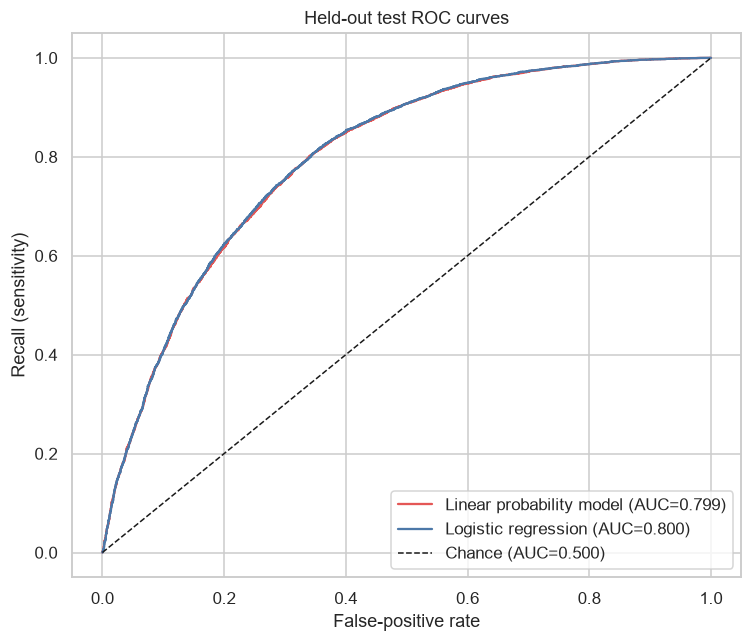

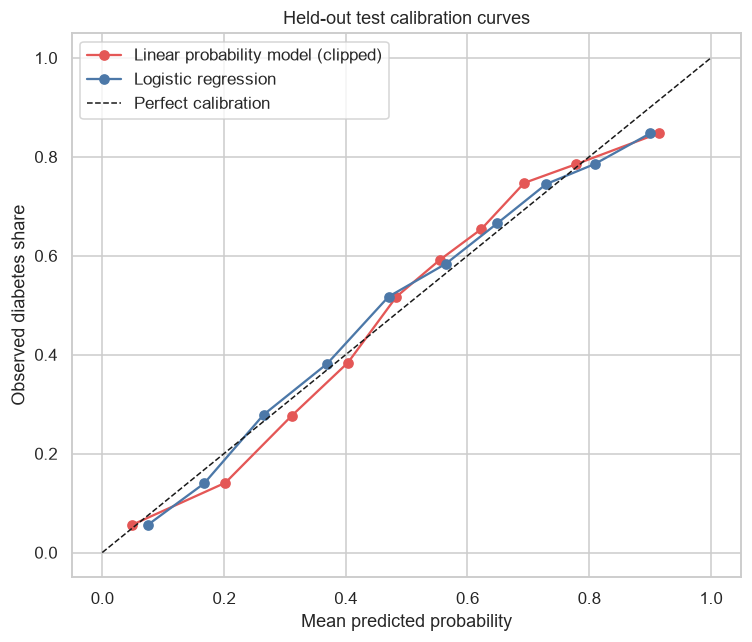

Test Brier scores — linear (clipped): 0.1831; logistic: 0.1817.


In [7]:
# Plot ROC curves for the linear and logistic models on the same held-out test rows.
fig, ax = plt.subplots(figsize=(7, 6))
for name, scores, color in [("Linear probability model", test_pred_a, "#E45756"),
                            ("Logistic regression", logit_test_a, "#4C78A8")]:
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_value = roc_auc_score(y_test, scores)
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC={auc_value:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC=0.500)")
ax.set(title="Held-out test ROC curves", xlabel="False-positive rate", ylabel="Recall (sensitivity)")
ax.legend()
plt.tight_layout()
plt.show()

# Calibration plots compare the average score with the observed positive rate in each bin.
fig, ax = plt.subplots(figsize=(7, 6))
for name, scores, color in [("Linear probability model (clipped)", np.clip(test_pred_a, 0, 1), "#E45756"),
                            ("Logistic regression", logit_test_a, "#4C78A8")]:
    observed, predicted = calibration_curve(y_test, scores, n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o", color=color, label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.set(title="Held-out test calibration curves", xlabel="Mean predicted probability", ylabel="Observed diabetes share")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Test Brier scores — linear (clipped): {brier_score_loss(y_test, np.clip(test_pred_a, 0, 1)):.4f}; logistic: {brier_score_loss(y_test, logit_test_a):.4f}.")

**Interpretation:** The held-out ROC curves are nearly identical (AUC 0.7994 for linear probability and 0.8003 for logistic). The logistic model has the lower Brier score, so its probabilities are modestly more accurate overall; neither curve makes the linear model's out-of-range issue disappear.

## 9. Save Part A Results

We save the linear-model evaluation using the same 11 core columns as the logistic evaluation tables. The additional 14%-prevalence estimates are shown in the notebook table above. The model bundle is saved in this notebook's folder, outside the Streamlit app's model directory.

In [8]:
# Keep the saved evaluation table schema consistent with the project's logistic evaluation tables.
save_rows = []
for label, cutoff in [("Default (0.50)", 0.50), (f"Chosen ({threshold_lpm_a:.2f})", threshold_lpm_a)]:
    result = classification_scores(y_test, test_pred_a, cutoff)
    save_rows.append({
        "Model": "Linear probability model (70k real rows)",
        "Threshold": label,
        "Accuracy": result["Accuracy"],
        "Recall (sensitivity)": result["Recall (sensitivity)"],
        "Specificity": result["Specificity"],
        "Precision": result["Precision"],
        "F1": result["F1"],
        "ROC AUC": result["ROC AUC"],
        "Brier score": result["Brier score (clipped)"],
        "Missed diabetes cases (false negatives)": result["Missed diabetes cases"],
        "Healthy people flagged (false positives)": result["Healthy people flagged"],
    })
eval_linprob = pd.DataFrame(save_rows)
csv_path = Path("diabetes_eval_linprob_70k.csv")
eval_linprob.to_csv(csv_path, index=False)
eval_linprob.to_sql("diabetes_eval_linprob_70k", con=engine, if_exists="replace", index=False)

linprob_bundle = {
    "model": lpm_a,
    "features": A_FEATURES,
    "threshold": threshold_lpm_a,
    "target_recall": TARGET_RECALL,
    "sklearn_version": __import__("sklearn").__version__,
    "kind": "linear_probability_model",
}
model_path = Path("linprob_70k.joblib")
joblib.dump(linprob_bundle, model_path)
print(f"Saved CSV: {csv_path.resolve()}")
print("Saved database table: diabetes_eval_linprob_70k")
print(f"Saved model bundle beside notebook: {model_path.resolve()}")

Saved CSV: C:\Users\PLP\Documents\ChatGPT\Data Science Fundamentals\notebooks\06_multilinearreg\diabetes_eval_linprob_70k.csv
Saved database table: diabetes_eval_linprob_70k
Saved model bundle beside notebook: C:\Users\PLP\Documents\ChatGPT\Data Science Fundamentals\notebooks\06_multilinearreg\linprob_70k.joblib


**Interpretation:** The evaluation CSV and MariaDB table each contain the linear model's default and OOF-selected threshold results. The model bundle is saved beside this notebook, not in the app's model directory.

## 10. Prepare Part B: Regress BMI

BMI is continuous, so regression can describe how it varies with the survey answers. We use the 20 other predictors, excluding both `BMI` and the diabetes label. The same saved train/test split is retained; model fitting and five-fold cross-validation use training rows only.

In [9]:
# Select the 20 predictors available after removing BMI and the diabetes outcome.
B_FEATURES = [c for c in train_df.columns if c not in [TARGET, "BMI"]]
if len(B_FEATURES) != 20:
    raise ValueError(f"Expected 20 BMI predictors, found {len(B_FEATURES)}.")
Xb_train = train_df[B_FEATURES].astype(float)
yb_train = train_df["BMI"].astype(float)
Xb_test = test_df[B_FEATURES].astype(float)
yb_test = test_df["BMI"].astype(float)
print(f"BMI regression prepared with {len(B_FEATURES)} predictors and {len(Xb_train):,} training rows.")
print("BMI is the outcome; Diabetes_binary and BMI are excluded from the predictor list.")

BMI regression prepared with 20 predictors and 56,155 training rows.
BMI is the outcome; Diabetes_binary and BMI are excluded from the predictor list.


**Interpretation:** The BMI model uses 20 predictors, excluding BMI and Diabetes_binary, with 56,155 training respondents.

## 11. Fit BMI Regression and Compare with a Mean Baseline

We fit a `LinearRegression` pipeline and a `DummyRegressor` that always predicts the training-set mean BMI. Five-fold cross-validation reports training-only estimates; train and test scores are also shown separately.

In [10]:
# Fit the baseline and the multiple linear regression using training rows only.
bmi_model = make_linear_regression(B_FEATURES).fit(Xb_train, yb_train)
bmi_dummy = DummyRegressor(strategy="mean").fit(Xb_train, yb_train)

# Cross-validation refits scaling within each fold because it is inside the pipeline.
cv_bmi = cross_validate(make_linear_regression(B_FEATURES), Xb_train, yb_train,
                        cv=5, scoring={"MAE": "neg_mean_absolute_error",
                                       "RMSE": "neg_root_mean_squared_error",
                                       "R-squared": "r2"})
cv_summary = {
    "MAE": -cv_bmi["test_MAE"].mean(),
    "RMSE": -cv_bmi["test_RMSE"].mean(),
    "R-squared": cv_bmi["test_R-squared"].mean(),
}

bmi_rows=[]
for name, estimator in [("Mean baseline", bmi_dummy), ("Multiple linear regression", bmi_model)]:
    for split, frame, target in [("Train", Xb_train, yb_train), ("Test", Xb_test, yb_test)]:
        pred=estimator.predict(frame)
        bmi_rows.append({"Model":name,"Split":split,**regression_scores(target,pred)})
bmi_scores=pd.DataFrame(bmi_rows)
display(bmi_scores.round(3).style.hide(axis="index"))
display(pd.DataFrame([cv_summary]).rename_axis("Training 5-fold CV").round(3).style.hide(axis="index"))
print("BMI regression and mean baseline scored; only training folds were used for cross-validation.")

Model,Split,MAE,RMSE,R-squared
Mean baseline,Train,5.317000,7.252000,0.000000
Mean baseline,Test,5.295000,7.270000,-0.000000
Multiple linear regression,Train,4.890000,6.751000,0.133000
Multiple linear regression,Test,4.915000,6.798000,0.126000


MAE,RMSE,R-squared
4.891000,6.752000,0.133000


BMI regression and mean baseline scored; only training folds were used for cross-validation.


**Interpretation:** The BMI regression improves over the mean baseline but explains a modest share of variation: test MAE 4.915, RMSE 6.798 and R² 0.126. Five-fold training CV R² is 0.133, close to the test result.

## 12. BMI Regression Coefficients with Robust Uncertainty

We refit the OLS form on the standardized training predictors and use HC3 robust standard errors. For a standardized feature, a coefficient is the expected BMI difference associated with a one-standard-deviation increase, holding the other modeled features fixed. These are associations, not causes.

In [11]:
# Fit the BMI OLS model on training rows only, using the pipeline's training-fitted transformation.
prep_b = bmi_model.named_steps["prep"]
Zb_train = prep_b.transform(Xb_train)
B_NAMES = list(prep_b.get_feature_names_out())
Zb_train_df = pd.DataFrame(Zb_train, columns=B_NAMES, index=Xb_train.index)
ols_b = sm.OLS(yb_train, sm.add_constant(Zb_train_df, has_constant="add")).fit(cov_type="HC3")
ci_b = ols_b.conf_int()
coef_b = pd.DataFrame({
    "Feature": B_NAMES,
    "BMI coefficient": ols_b.params[B_NAMES].to_numpy(),
    "95% CI lower": ci_b.loc[B_NAMES, 0].to_numpy(),
    "95% CI upper": ci_b.loc[B_NAMES, 1].to_numpy(),
    "p-value": ols_b.pvalues[B_NAMES].to_numpy(),
}).sort_values("BMI coefficient", ascending=False)
display(coef_b.round(4).style.hide(axis="index"))
print("BMI coefficients describe conditional associations in this survey sample; they do not establish causes.")

Feature,BMI coefficient,95% CI lower,95% CI upper,p-value
HighBP,2.746400,2.621300,2.871500,0.000000
DiffWalk,2.635500,2.469300,2.801700,0.000000
CholCheck,1.250400,0.924100,1.576700,0.000000
GenHlth,0.962900,0.888600,1.037200,0.000000
HighChol,0.603600,0.483400,0.723800,0.000000
AnyHealthcare,0.321900,0.029000,0.614900,0.031300
Income,0.071500,0.000100,0.143000,0.049700
Veggies,0.029300,-0.114200,0.172800,0.689200
Sex,-0.014300,-0.130400,0.101700,0.808600
Education,-0.035900,-0.101000,0.029200,0.279600


BMI coefficients describe conditional associations in this survey sample; they do not establish causes.


**Interpretation:** The strongest positive training associations with BMI are HighBP (+2.746 BMI units) and DiffWalk (+2.636), followed by CholCheck (+1.250). These adjusted associations do not establish that any answer causes BMI to change.

## 13. BMI Regression Diagnostics

The residual-versus-fitted plot checks curvature and changing spread. A Q-Q plot compares residual quantiles with a normal distribution, while the histogram shows the residual shape. The Breusch-Pagan test checks for changing residual variance. These diagnostics are computed on training rows.

Breusch-Pagan LM statistic: 929.396; p-value: 4.34e-184


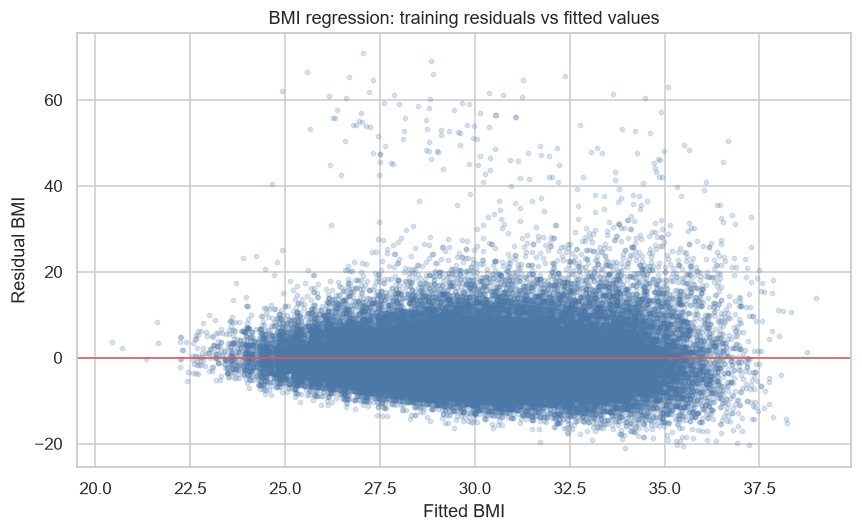

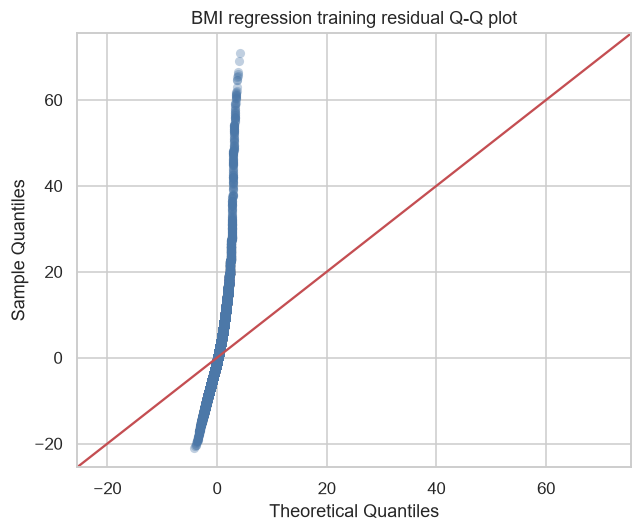

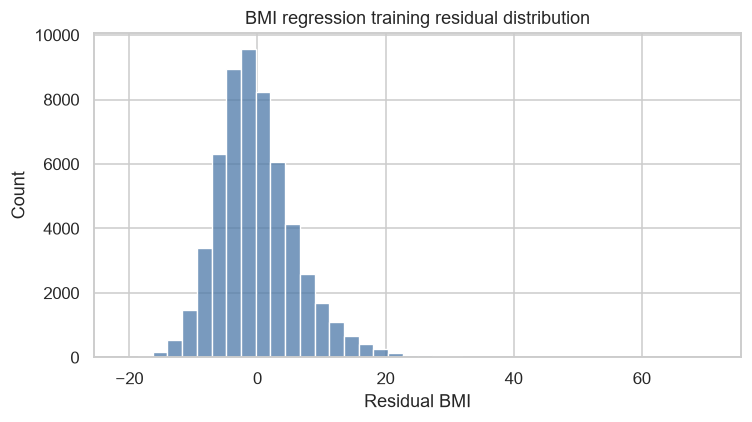

Training share with BMI ≥ 60: 0.47%; test share: 0.47%.


In [12]:
# Calculate training residuals and a Breusch-Pagan test using training predictors.
bmi_train_fit = bmi_model.predict(Xb_train)
bmi_train_resid = yb_train.to_numpy() - bmi_train_fit
bp_b = het_breuschpagan(bmi_train_resid, sm.add_constant(Zb_train_df, has_constant="add"))
print(f"Breusch-Pagan LM statistic: {bp_b[0]:.3f}; p-value: {bp_b[1]:.3g}")

# Residuals versus fitted values reveal systematic patterns and changing spread.
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(bmi_train_fit, bmi_train_resid, s=8, alpha=0.2, color="#4C78A8")
ax.axhline(0, color="#E45756", lw=1)
ax.set(title="BMI regression: training residuals vs fitted values", xlabel="Fitted BMI", ylabel="Residual BMI")
plt.tight_layout(); plt.show()

# Q-Q plot checks whether residual tails depart from a normal reference.
fig, ax = plt.subplots(figsize=(6, 5))
sm.qqplot(bmi_train_resid, line="45", ax=ax, markerfacecolor="#4C78A8", markeredgecolor="none", alpha=0.35)
ax.set_title("BMI regression training residual Q-Q plot")
plt.tight_layout(); plt.show()

# Histogram shows asymmetry and heavy tails directly.
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(bmi_train_resid, bins=40, color="#4C78A8", ax=ax)
ax.set(title="BMI regression training residual distribution", xlabel="Residual BMI", ylabel="Count")
plt.tight_layout(); plt.show()
print(f"Training share with BMI ≥ 60: {(yb_train >= 60).mean():.2%}; test share: {(yb_test >= 60).mean():.2%}.")

**Interpretation:** The residual diagnostics and very small Breusch–Pagan p-value indicate non-constant residual spread; BMI regression assumptions are imperfect. BMI ≥ 60 represents 0.47% of both splits (262 training rows), so the sensitivity check tests a small tail rather than a broad data-cleaning change.

## 14. BMI Sensitivity Checks

BMI is right-skewed. We compare the main model with (1) a model trained on `log(BMI)` and retransformed to the original scale using a training-only smearing factor, and (2) a model trained after excluding only training rows with BMI ≥ 60. Both sensitivity models are evaluated on the unchanged test set.

In [13]:
# Log-BMI model: fit on the log target, then use a training-only smearing correction on the original scale.
log_bmi_model = make_linear_regression(B_FEATURES).fit(Xb_train, np.log(yb_train))
log_train_resid = np.log(yb_train.to_numpy()) - log_bmi_model.predict(Xb_train)
smearing_factor = float(np.mean(np.exp(log_train_resid)))
log_test_pred = np.exp(log_bmi_model.predict(Xb_test)) * smearing_factor

# High-BMI sensitivity: remove BMI >= 60 only from the training fit, never from the test set.
keep_train = yb_train < 60
bmi_without_extremes = make_linear_regression(B_FEATURES).fit(Xb_train.loc[keep_train], yb_train.loc[keep_train])
extreme_test_pred = bmi_without_extremes.predict(Xb_test)

sensitivity_rows=[]
for name, prediction in [("Main BMI model", bmi_model.predict(Xb_test)),
                         ("Log-BMI with training smearing correction", log_test_pred),
                         ("Fit without training BMI ≥ 60", extreme_test_pred)]:
    sensitivity_rows.append({"Model":name,**regression_scores(yb_test,prediction)})
sensitivity_bmi=pd.DataFrame(sensitivity_rows)
display(sensitivity_bmi.round(3).style.hide(axis="index"))
print(f"Training rows retained for high-BMI sensitivity fit: {int(keep_train.sum()):,} of {len(keep_train):,}.")
print(f"Log-model smearing factor estimated from training rows: {smearing_factor:.4f}.")

Model,MAE,RMSE,R-squared
Main BMI model,4.915000,6.798000,0.126000
Log-BMI with training smearing correction,4.902000,6.794000,0.127000
Fit without training BMI ≥ 60,4.888000,6.799000,0.125000


Training rows retained for high-BMI sensitivity fit: 55,893 of 56,155.
Log-model smearing factor estimated from training rows: 1.0220.


**Interpretation:** The log-BMI model is marginally better on test MAE (4.902 vs. 4.915) and RMSE (6.794 vs. 6.798), while excluding training BMI ≥ 60 gives MAE 4.888 but slightly lower R² (0.125 vs. 0.126). These small differences do not materially change the conclusion.

## 15. Summary

### What we did

- **Part A:** compared an OLS linear probability model with the saved 70k logistic model on the same 14 features and 14,039 held-out rows.
- **Part B:** modeled BMI with 20 predictors, training-only cross-validation, robust coefficient estimates, diagnostics and two sensitivity checks.

### Key results

- Linear probability model test Recall: **0.8507**; Specificity: **0.5983**; ROC AUC: **0.7994**.
- Raw linear probability scores outside 0–1: **3.21% below 0 and 1.57% above 1** on training; **3.26% below 0 and 1.72% above 1** on test.
- BMI regression test MAE: **4.915**; RMSE: **6.798**; R-squared: **0.126**. Training five-fold CV R-squared: **0.133**.
- HighBP and DiffWalk have the largest positive BMI coefficients in this fitted model; the log-BMI and high-BMI-exclusion results are close to the main model.

### Limitations

Answers are self-reported, and the target is diagnosed diabetes; undiagnosed diabetes is labeled 0. The dataset is a 2015 US survey. Balanced-set precision and accuracy can be optimistic. The classifier estimates current diagnosed diabetes, not future diabetes. Linear-model coefficients show associations, not causes. OLS's binary-outcome limitations remain even when its ranking is useful.

### Next step

Run `notebooks/08_model_comparison/08_model_comparison.ipynb` to compare models and decide which one the app should use.